# Which GPU work did PyTorch launch?

`capture` returns `prof.events()` unchanged. Locally, `rows` keeps every event
once, in its original order, with its original unique row index.
Object references (`cpu_parent`, `cpu_children`, `kernels`) are replaced by
`launcher_id`, which points to another row in this same table:

- CPU event: its PyTorch `cpu_parent` row index.
- GPU kernel/copy/memset: the CUDA runtime or driver row matched by
  `correlation_id`; if no unique launch row exists, fall back to the CPU frontend
  event matched by `linked_correlation_id`.
- Other device events: use their `linked_correlation_id`, when available.

Follow `launcher_id` to trace any kernel back through the CPU operations that
led to it, or filter on `launcher_id` to inspect an event's direct children.
The resulting chain includes the launch API call, for example
`aten::mm -> cudaLaunchKernel -> kernel`. No execution groups are created.
Frontend and runtime/driver correlation lookups are kept separate within each
`node_id`. Missing or ambiguous matches use the frontend fallback where possible;
otherwise the link stays null. All events are retained.

Module hooks record `forward::<module_fqn>` scopes. Autograd node hooks
restore the same module path as `backward::<module_fqn>` during backward.
Follow a kernel's `launcher_id` chain to find its nearest module annotation.
If no such annotation exists, its module is unattributed. The existing
`train::<phase>` scopes also remain in the trace.


In [1]:
import torch
from models.transformer import ModelParameters, build

# Built on CPU; capture moves it to the GPU on Modal.
model_parameters = ModelParameters(
    vocab_size=1000, sequence_length=64, num_layers=5,
    d_model=64, d_ff=64, num_heads=2, rope_theta=10000,
    device="cpu", dtype="torch.float32",
)
torch.manual_seed(0)
model = build(model_parameters)
tokens = torch.randint(
    0, model_parameters.vocab_size, (8, model_parameters.sequence_length),
    generator=torch.Generator().manual_seed(0),
)

In [2]:
from contextlib import ExitStack, contextmanager
from threading import local


@contextmanager
def module_scopes(model, root="model"):
    """Record module scoped execution stages for eager modules.

    Convention and organization
    ---------------------------
    A module scoped execution stage is a CPU user_annotation event created by
    record_function. Its name is <phase>::<module_fqn>, where phase is forward
    or backward and module_fqn is a named_modules path prefixed by root:

        forward::model                  # root module
        forward::model.tblocks.0        # submodule
        backward::model.tblocks.0       # same submodule during backward

    The same convention applies at every module depth. Forward stages nest
    according to actual module calls. Backward stages restore the recorded
    root-to-owner module path around each owned autograd node's execution.
    A stage name can therefore occur in multiple event rows; the original row
    index identifies each occurrence, not the stage name or module FQN.

    train::<phase> annotations describe whole training phases; module scoped
    execution stages describe module work within a phase. Backward workers may
    lack the outer train::backward ancestor, so the stage name encodes its phase
    directly. These annotations label execution; they are not autograd nodes.
    Following a kernel's launcher_id chain finds its nearest module scoped
    execution stage. If none exists, that kernel stays module-unattributed.

    Recording and ownership
    -----------------------
    Forward hooks track the active module path. TorchFunctionMode observes each
    operation's new autograd nodes and attaches that path to them once. Node
    pre/post hooks restore the path on the backward worker thread, surrounding
    its CPU operations and CUDA launches with backward::<FQN> annotations.
    Keep this context open for both forward and backward.

    Input graph nodes and nodes already owned by a child module are not claimed.
    AccumulateGrad is deliberately unowned: a shared parameter can accumulate
    contributions from several modules. Loss/optimizer work outside the module
    calls gets no module label. A kernel without a module annotation anywhere
    on its launcher_id chain remains unattributed.

    Shared modules use an alias below the active caller when possible, otherwise
    the first named_modules path. Aliases under the same caller are ambiguous
    to module hooks and use the first path. Direct .forward() calls bypass hooks.
    Compiled graphs and checkpoint recomputation are outside this eager workflow.
    All installed hooks and still-open scopes are cleaned up on context exit.
    No tensors or gradients are replaced.
    """
    import torch
    from torch.overrides import TorchFunctionMode
    from torch.profiler import record_function
    from torch.utils._pytree import tree_leaves

    # Discover module identities and their fully qualified aliases.
    aliases = {}
    for name, module in model.named_modules(remove_duplicate=False):
        aliases.setdefault(module, []).append(f"{root}.{name}" if name else root)

    state = local()
    handles, owned_nodes, open_scopes = [], set(), {}

    # Emit stages from outermost module to owner; ExitStack closes in reverse.
    def open_path(phase, path):
        scopes = ExitStack()
        open_scopes[scopes] = None
        for fqn in path:
            scopes.enter_context(record_function(f"{phase}::{fqn}"))
        return scopes

    def close_path(scopes):
        try:
            scopes.close()
        finally:
            open_scopes.pop(scopes, None)

    # Restore backward stages on the thread executing each owned autograd node.
    def attach_node(node, path):
        # Retain node objects: Python object IDs may be reused between operations.
        owned_nodes.add(node)
        node.metadata["launchpad_module"] = {
            "module_fqn": path[-1], "module_path": list(path),
        }
        running = local()

        def before(grad_outputs):
            if not hasattr(running, "stack"):
                running.stack = []
            running.stack.append(open_path("backward", path))

        def after(grad_inputs, grad_outputs):
            close_path(running.stack.pop())

        handles.append(node.register_prehook(before))
        handles.append(node.register_hook(after))

    def grad_nodes(value):
        return {tensor.grad_fn for tensor in tree_leaves(value)
                if isinstance(tensor, torch.Tensor) and tensor.grad_fn is not None}

    # During forward, assign new nodes once to the active module path.
    class CaptureAutogradNodes(TorchFunctionMode):
        def __torch_function__(self, func, types, args=(), kwargs=None):
            kwargs = kwargs or {}
            stack = getattr(state, "stack", [])
            if not stack:
                return func(*args, **kwargs)

            path = tuple(fqn for _, fqn, _ in stack)
            boundary = grad_nodes((args, kwargs))
            output = func(*args, **kwargs)
            pending, visited = list(grad_nodes(output)), set()
            while pending:
                node = pending.pop()
                if node in boundary or node in owned_nodes or node in visited:
                    continue
                visited.add(node)
                if node.name() == "torch::autograd::AccumulateGrad":
                    continue
                attach_node(node, path)
                pending.extend(parent for parent, _ in node.next_functions if parent is not None)
            return output

    # Forward hooks open/close one stage per module invocation.
    def enter(module, args):
        if not hasattr(state, "stack"):
            state.stack = []
        paths = aliases[module]
        caller = state.stack[-1][1] if state.stack else None
        candidates = [path for path in paths if caller and path.startswith(caller + ".")]
        fqn = (candidates or paths)[0]
        state.stack.append((module, fqn, open_path("forward", [fqn])))

    def leave(module, args, output):
        stack = getattr(state, "stack", [])
        if stack and stack[-1][0] is module:
            close_path(stack.pop()[2])

    # Install instrumentation for this context only; clean up even on failure.
    try:
        for module in aliases:
            handles.append(module.register_forward_pre_hook(enter, prepend=True))
            handles.append(module.register_forward_hook(leave, always_call=True))
        with CaptureAutogradNodes():
            yield
    finally:
        for handle in handles:
            handle.remove()
        # An autograd exception may skip a node's post-hook.
        for scopes in reversed(list(open_scopes)):
            close_path(scopes)
        owned_nodes.clear()


In [3]:
from profile_events import app, image


@app.function(image=image, gpu="T4", timeout=300)
def capture(model, tokens, warmup_steps=5) -> list:
    """Warm up full training steps, then profile one step on the same model.

    Warmup includes forward, loss, backward and optimizer.step so CUDA libraries
    and optimizer state are initialized. Warmup events are not recorded.
    """
    import torch
    from torch import nn
    from torch.profiler import ProfilerActivity, profile, record_function

    torch.manual_seed(0)
    model = model.to("cuda")
    tokens = tokens.to("cuda")
    model.train()
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
    # Next-token prediction: each position predicts the following input token.
    targets = tokens[:, 1:].reshape(-1)

    def train_step():
        with record_function("train::zero_grad"):
            optimizer.zero_grad(set_to_none=True)
        with record_function("train::forward"):
            logits = model(tokens)
        with record_function("train::loss"):
            loss = nn.functional.cross_entropy(
                logits[:, :-1, :].reshape(-1, logits.shape[-1]), targets
            )
        with record_function("train::backward"):
            loss.backward()
        with record_function("train::optimizer_step"):
            optimizer.step()

    # Complete warmup before profiling: no queued warmup work enters the trace.
    for _ in range(warmup_steps):
        train_step()
    torch.cuda.synchronize()

    with profile(
        activities=[ProfilerActivity.CPU, ProfilerActivity.CUDA],
        record_shapes=True,
        with_stack=False,
        with_flops=True,
        profile_memory=True,
    ) as prof, module_scopes(model):
        train_step()
        # Kernels run asynchronously. Wait for them inside the profiler so every launched
        # activity has finished, and been recorded, before collection stops.
        torch.cuda.synchronize()
    # The FunctionEvents themselves: they pickle with their cpu_parent/cpu_children references.
    return list(prof.events())

In [4]:
with app.run():
    function_events = capture.remote(model, tokens, warmup_steps=5)
print(f"{len(function_events)} events")

11064 events


In [5]:
import pandas as pd


def _cpu_correlations(events, activity_types):
    """Map (node, correlation) to a CPU row ID; ambiguous matches stay None."""
    lookup = {}
    for event in events:
        if not event.is_cpu or event.activity_type not in activity_types:
            continue
        if pd.isna(event.correlation_id) or event.correlation_id == 0:
            continue
        key = (event.node_id, event.correlation_id)
        lookup[key] = event.Index if key not in lookup else None
    return lookup


def _validate_launchers(parents, cpu_ids):
    """Reject missing/non-CPU parents and cycles in O(n), without recursion."""
    for index, parent in parents.items():
        if parent is not None and parent not in cpu_ids:
            raise ValueError(f"Event {index} refers to missing or non-CPU launcher {parent}")

    checked = set()
    for index in parents:
        current, visiting = index, set()
        while current is not None and current not in checked:
            if current in visiting:
                raise ValueError("Launcher links contain a cycle")
            visiting.add(current)
            current = parents[current]
        checked.update(visiting)


def link_events(frame):
    """Connect events to their immediate CPU origin using original row IDs.

    ID reference
    ------------
    frame.index
        Unique integer row ID assigned when building the original event table.
        This is the identity used for navigation with frame.loc[row_id]. It is
        NOT a profiler correlation ID. Preserve it when filtering the table.
    launcher_id
        A row ID in this same table, or NA when no parent is known. On input,
        CPU rows must contain their PyTorch cpu_parent converted from an object
        reference to its row ID. On output, CPU parents are preserved and GPU
        rows point to their matched CPU launch call or frontend operation.
        For a CPU row, "launcher" means its enclosing CPU parent scope; it
        does not imply that every CPU event launches GPU work.
    correlation_id
        The original FunctionEvent.id, renamed during table construction.
        CPU frontend operations (cpu_op) and scopes (user_annotation) use
        PyTorch's counter. CUDA runtime/driver calls and GPU work use CUPTI's
        counter: a GPU activity shares its launch call's correlation ID.
        These counters can collide, so frontend and launch lookups are kept
        separate. A correlation ID is not a unique event-row identifier.
    linked_correlation_id
        For CUDA runtime/driver calls and GPU work, identifies the originating
        CPU frontend operation's correlation_id. It is not that operation's
        row ID, and does not identify the intermediate CUDA launch row.
        Zero or missing values mean there is no usable correlation link.
    node_id
        Profiler node identifier used to keep correlations from different
        nodes separate. Every lookup uses (node_id, correlation_id); absent
        or missing node IDs use -1. This is neither a row ID nor a GPU ID.
    external_id
        Raw profiler external-correlation metadata, retained unchanged if
        present. It is not a row ID and this function does not use it.

    Linking rules
    -------------
    1. CPU events keep the cpu_parent row links already computed by PyTorch.
    2. GPU kernels, copies and memsets first match correlation_id against CPU
       cuda_runtime/cuda_driver rows, inserting the CUDA API call in the path.
    3. If there is no unique launch match, match linked_correlation_id against
       CPU cpu_op/user_annotation rows instead. Other device events only use
       this fallback; GPU annotation spans must not join unrelated launch IDs.

    Missing or duplicate correlation matches are unresolved, never selected
    arbitrarily. After fallback, unresolved events retain launcher_id=NA.
    No time-based parent inference or cross-thread CPU ancestry is added.

    For example, following launcher_id from a kernel might visit original row
    IDs 50 -> 40 -> 30 -> 20, representing:
        GPU kernel -> cudaLaunchKernel -> aten::mm -> enclosing CPU scope
    Read the path in reverse for execution provenance. To find direct children
    of row 30, use rows.loc[rows["launcher_id"].eq(30)].

    Returns a new DataFrame in O(n) time and space, preserving every row, its
    index, order and other columns. Only launcher_id is updated (nullable
    Int64); no groups or duplicated ancestor rows are created. Raises
    ValueError for non-unique row IDs, missing/non-CPU parents, or cycles.
    """
    if not frame.index.is_unique:
        raise ValueError("Event row indices must be unique")

    # Only read linking fields, leaving large metadata (stacks, shapes) untouched.
    columns = ["activity_type", "correlation_id", "linked_correlation_id", "launcher_id"]
    events = list(frame[columns].assign(
        is_cpu=frame["device_type"].map(str).eq("DeviceType.CPU"),
        node_id=frame.get("node_id", pd.Series(-1, index=frame.index)).fillna(-1),
    ).itertuples())

    # PyTorch frontend IDs and CUPTI launch IDs are separate namespaces.
    frontend = _cpu_correlations(events, {"cpu_op", "user_annotation"})
    launches = _cpu_correlations(events, {"cuda_runtime", "cuda_driver"})
    gpu_work = {"kernel", "gpu_memcpy", "gpu_memset"}

    parents = {}
    for event in events:
        if event.is_cpu:
            parents[event.Index] = int(event.launcher_id) if pd.notna(event.launcher_id) else None
            continue

        launcher = None
        # Annotation spans must not match unrelated CUDA launch IDs.
        if event.activity_type in gpu_work and pd.notna(event.correlation_id):
            launcher = launches.get((event.node_id, event.correlation_id))
        if launcher is None and pd.notna(event.linked_correlation_id):
            launcher = frontend.get((event.node_id, event.linked_correlation_id))
        parents[event.Index] = launcher

    _validate_launchers(parents, {event.Index for event in events if event.is_cpu})
    return frame.assign(launcher_id=pd.array(list(parents.values()), dtype="Int64"))


In [6]:
position = {id(event): i for i, event in enumerate(function_events)}
raw_rows = (
    pd.DataFrame([vars(event) for event in function_events])
    .rename(columns={"id": "correlation_id"})
    .drop(columns=["cpu_parent", "cpu_children", "kernels"])
    .assign(launcher_id=pd.array(
        [position.get(id(event.cpu_parent)) for event in function_events], dtype="Int64"))
    .rename_axis("index")
)
rows = link_events(raw_rows)
# Every original event stays at the same unique row index.
assert rows.index.equals(raw_rows.index)

# Every kernel execution, including those without a known launcher.
kernel_ids = rows.index[rows["activity_type"].eq("kernel")].tolist()
kernels = rows.loc[kernel_ids]


## What each id is

`correlation_id` is `FunctionEvent.id`, which `_parse_kineto_results` fills with
`kineto_event.correlation_id()`. What it counts depends on the kind of row:

| Row (`activity_type`) | `correlation_id` | `linked_correlation_id` | `external_id` |
| --- | --- | --- | --- |
| Frontend: op or `record_function` scope (`cpu_op`, `user_annotation`) | PyTorch's own counter | 0 | `correlation_id` |
| Launch call on the CPU (`cuda_runtime`, `cuda_driver`) | CUPTI's counter | the op's `correlation_id` | `linked_correlation_id` |
| GPU work (`kernel`, `gpu_memcpy`, `gpu_memset`) | CUPTI's counter, equal to its launch call's | the op's `correlation_id` | `linked_correlation_id` |
| GPU span of a scope (`gpu_user_annotation`) | its scope's `correlation_id` | 0 | `correlation_id` |
| Profiler overhead (`overhead`) | reuses the `correlation_id` of the op it interrupted | 0 | 0 |

Two counters share the `correlation_id` column, so every lookup by it is restricted to one kind of row:
in one capture `Optimizer.step`'s GPU span and an unrelated launch call were both 1912.
`external_id` holds no value of its own: `KinetoEvent::externalId()` returns
`linked_correlation_id` when there is one, else `correlation_id`.

In [7]:
rows[rows['name'].str.startswith('aten::')].columns

Index(['correlation_id', 'node_id', 'name', 'overload_name', 'trace_name',
       'time_range', 'thread', 'fwd_thread', 'count', 'input_shapes',
       'concrete_inputs', 'kwinputs', 'stack', 'scope', 'use_device',
       'cpu_memory_usage', 'device_memory_usage', 'is_async', 'is_remote',
       'sequence_nr', 'device_type', 'device_index', 'device_resource_id',
       'is_legacy', 'flops', 'is_user_annotation', 'is_python_function',
       'activity_type', 'self_cpu_percent', 'total_cpu_percent',
       'total_device_percent', '_metadata_json', 'flow_id', 'flow_type',
       'flow_start', 'external_id', 'linked_correlation_id', 'event_metadata',
       'structured_input_shapes', 'structured_input_strides', 'input_dtypes',
       'python_id', 'python_parent_id', 'python_module_id', 'launcher_id'],
      dtype='str')

In [8]:
# Inspect one kernel's full provenance using original row IDs.
# The nearest module annotation is its owner; no annotation means unattributed.
if kernel_ids:
    kernel_index = kernel_ids[0]  # Change this to any kernel row ID.
    branch_ids, current = [], kernel_index
    while pd.notna(current):
        branch_ids.append(current)
        current = rows.loc[current, "launcher_id"]
    branch = rows.loc[branch_ids]  # Kernel -> CPU root.
    scopes = branch.loc[
        branch["activity_type"].eq("user_annotation")
        & branch["name"].str.startswith(("forward::", "backward::"), na=False)
    ]
    scope_label = scopes.iloc[0]["name"] if not scopes.empty else None
    print("Module scope:", scope_label or "unattributed")
    display(branch.iloc[::-1])  # CPU root -> CUDA launch -> kernel.


Module scope: forward::model.embedding


,correlation_id,node_id,name,overload_name,trace_name,time_range,thread,fwd_thread,count,input_shapes,...,external_id,linked_correlation_id,event_metadata,structured_input_shapes,structured_input_strides,input_dtypes,python_id,python_parent_id,python_module_id,launcher_id
index,,,,,,,,,,,,,,,,,,,,,
2,3,-1,train::forward,,train::forward,<torch.autograd.profiler_util.Interval object ...,1,0,1,[],...,3,0,None,[],[],[],-1,-1,-1,<NA>
3,4,-1,forward::model,,forward::model,<torch.autograd.profiler_util.Interval object ...,1,0,1,[],...,4,0,None,[],[],[],-1,-1,-1,2
4,5,-1,forward::model.embedding,,forward::model.embedding,<torch.autograd.profiler_util.Interval object ...,1,0,1,[],...,5,0,None,[],[],[],-1,-1,-1,3
5,6,-1,aten::index,,aten::index,<torch.autograd.profiler_util.Interval object ...,1,0,1,"[[1000, 64], []]",...,6,0,None,"[[1000, 64], []]","[[64, 1], []]","[float, ]",-1,-1,-1,4
10,11,-1,cudaLaunchKernel,,cudaLaunchKernel,<torch.autograd.profiler_util.Interval object ...,1,0,1,[],...,6,6,None,[],[],[],-1,-1,-1,5
11,11,-1,"void at::native::vectorized_gather_kernel<16, ...",,"void at::native::vectorized_gather_kernel<16, ...",<torch.autograd.profiler_util.Interval object ...,1,0,1,[],...,6,6,None,[],[],[],-1,-1,-1,10


In [9]:
# Check every kernel's path to its highest module scoped execution stage.
# Run against the current rows; unattributed kernels are retained separately.
root_module = "model"  # Must match module_scopes(..., root=...).
parents = rows["launcher_id"].to_dict()
stage_names = rows.loc[
    rows["activity_type"].eq("user_annotation")
    & rows["name"].str.startswith(("forward::", "backward::"), na=False),
    "name",
].to_dict()
checks = []
for kernel_id in kernel_ids:
    branch, stages, current = [], [], kernel_id
    while pd.notna(current):
        branch.append(current)
        if current in stage_names:
            stages.append(current)
        current = parents[current]

    highest_stage_id = stages[-1] if stages else None
    highest_stage = stage_names.get(highest_stage_id)
    status = "unattributed"
    if stages:
        phase = stage_names[stages[0]].split("::", 1)[0]
        status = "complete" if highest_stage == f"{phase}::{root_module}" else "missing_root"
        # Keep every intermediate event, ending at the highest module stage.
        branch = branch[:branch.index(highest_stage_id) + 1]
    checks.append((kernel_id, status, highest_stage_id, highest_stage, branch))

kernel_paths = pd.DataFrame(checks, columns=[
    "kernel_id", "status", "highest_stage_id", "highest_stage", "branch",
]).set_index("kernel_id")
kernel_paths["highest_stage_id"] = pd.array(kernel_paths["highest_stage_id"], dtype="Int64")
display(kernel_paths["status"].value_counts())
missing_roots = kernel_paths.index[kernel_paths["status"].eq("missing_root")].tolist()
assert not missing_roots, f"Attributed kernels missing phase::{root_module}: {missing_roots}"
# Full path for a kernel, ordered highest stage -> kernel:
# rows.loc[kernel_paths.loc[kernel_id, "branch"][::-1]]


status
complete        713
unattributed    114
Name: count, dtype: int64

In [10]:
import math


def _execution_context(event, inherited, root):
    """Return (phase, full owner FQN, owner stage row ID) for one tree node."""
    phase, owner, stage_id = inherited
    if str(event.device_type) != "DeviceType.CPU":
        return inherited
    name = event.name
    if event.activity_type == "user_annotation":
        if name.startswith("train::"):
            return name.removeprefix("train::"), None, None
        label_phase, separator, fqn = name.partition("::")
        if separator and (fqn == root or fqn.startswith(root + ".")):
            return label_phase, fqn, event.Index
        if name.startswith("Optimizer.step#") and owner is None:
            return "optimizer_step", None, None
    if name.startswith("autograd::engine::evaluate_function:"):
        return "backward", owner if phase == "backward" else None, stage_id if phase == "backward" else None
    return phase, owner, stage_id


def aggregate_kernels(rows, depth=None, *, root="model"):
    """Partition kernel events by phase/module depth and roll up ATen FLOPs.

    Input
    -----
    rows is the complete event table returned by link_events, with unique
    original integer row IDs and launcher_id parent links. No events are
    removed from or added to rows. Module scoped execution stages use labels
    <phase>::<module_fqn>. GPU timestamps come from time_range.start/end in us.

    depth counts FQN components, including root: 1 = model, 2 = model.tblocks,
    3 = model.tblocks.0; None retains the full owning FQN. A container prefix
    need not have a recorded scope: it is a logical group, not a fabricated
    event. Direct work in a shallower module stays in that module's group.
    Repeated occurrences of the same phase/FQN merge. Kernel membership is
    exclusive: no group includes kernels already assigned to another group.

    Ownership and timing
    --------------------
    The nearest module stage owns a kernel. Without one, module_fqn is
    <unattributed>. Phase comes from the stage, train::<phase>, or a backward
    engine/optimizer scope; otherwise it is unscoped. All kernel rows appear
    once, including those with missing links. Copies and memsets are excluded.
    GPU span = latest end - earliest start (including gaps). GPU time is the
    sum of kernel durations (overlapping launches contribute independently).

    FLOPs
    -----
    Only CPU aten:: operations with descendant kernels contribute. A positive
    finite reported flops value replaces the sum of all child estimates.
    Otherwise, child estimates pass up through intermediate event nodes.
    Thus nested reported estimates are suppressed by the outermost reported
    ancestor, siblings add, and one ATen launching many kernels counts once.
    Every contribution is identified by its original ATen row ID, never by
    operation name. No FLOP total is replicated on individual kernel rows.

    Returns
    -------
    groups: DataFrame indexed by (phase, module_fqn), with kernel_ids,
        owner_stage_ids, kernel_count, estimated_flops, flop_source_ids,
        gpu_start_us, gpu_end_us, gpu_span_us and gpu_time_us.
    kernels: Original kernel rows, at their original unique indices, augmented
        with phase, module_fqn, owner_fqn, owner_stage_id, gpu_start_us,
        gpu_end_us and duration_us. groups.kernel_ids references this table.
    flop_sources: Positive reported ATen estimates with descendant kernels,
        indexed by original ATen row ID. status is allocated, suppressed or
        unallocated. suppressed_by identifies the overriding ATen ancestor;
        contribution_flops is nonzero only for allocated estimates.
        spans_groups checks the caveat below, including suppressed estimates.

    Limitations
    -----------
    FLOPs are partial operation estimates, not measured GPU instructions.
    Zero/missing/nonfinite values mean unavailable here; zero output does not
    prove zero work. CPU-only branches without kernels are excluded, but a
    reported operation estimate cannot separate mixed CPU/GPU computation.

    Usually module stages enclose ATen operations. Hypothetically an estimated
    ATen ancestor could instead enclose several module stages whose kernels
    fall into different requested groups. Multiple kernels or shared weights
    alone do NOT imply this. We check actual descendant group membership and
    flag spans_groups=True. If such an estimate is unsuppressed, it remains
    unallocated rather than being divided or duplicated; its descendants are
    still suppressed. Inspect rows.loc[flop_sources.index] for the real source
    events. Allocated group totals can consequently change with depth; the
    allocated plus unallocated estimate stays conserved. Suppressed reports
    must never be added back to totals.

    Missing ancestry stays unattributed; no phase/module links are invented.
    A merged group's time span can include gaps between repeated invocations.
    Building and traversing the forest is O(events + kernels); no per-kernel
    ancestor walks or copies of entire subtrees are required.
    """
    if depth is not None and (isinstance(depth, bool) or not isinstance(depth, int) or depth < 1):
        raise ValueError("depth must be a positive integer or None")
    if not isinstance(root, str) or not root:
        raise ValueError("root must be a nonempty FQN")
    if not rows.index.is_unique:
        raise ValueError("Event row indices must be unique")

    # Read just the fields needed to build the forest and compute estimates.
    columns = ["name", "device_type", "activity_type", "launcher_id", "time_range", "flops"]
    events = {event.Index: event for event in rows.reindex(columns=columns).itertuples()}
    parents = {index: int(event.launcher_id) if pd.notna(event.launcher_id) else None
               for index, event in events.items()}
    cpu_ids = {index for index, event in events.items() if str(event.device_type) == "DeviceType.CPU"}
    _validate_launchers(parents, cpu_ids)
    children = {index: [] for index in events}
    roots = []
    for index, parent in parents.items():
        if parent is None:
            roots.append(index)
        else:
            children[parent].append(index)

    # Top-down: carry phase/module ownership without materializing branches.
    order, contexts, group_keys = [], {}, {}
    pending = list(reversed(roots))
    while pending:
        index = pending.pop()
        inherited = contexts.get(parents[index], ("unscoped", None, None))
        phase, owner, stage_id = _execution_context(events[index], inherited, root)
        contexts[index] = phase, owner, stage_id
        if owner is None:
            group_fqn = "<unattributed>"
        elif depth is None or owner == root:
            group_fqn = owner
        else:
            components = [root] + owner[len(root) + 1:].split(".")
            group_fqn = ".".join(components[:depth])
        group_keys[index] = phase, group_fqn
        order.append(index)
        pending.extend(reversed(children[index]))

    kernel_ids = [index for index, event in events.items() if event.activity_type == "kernel"]
    kernel_set = set(kernel_ids)
    # A subtree needs just one group key or a mixed marker, not a set of kernels.
    mixed = object()
    destinations, kernel_counts, effective_flops, reported = {}, {}, {}, {}
    for index in reversed(order):
        destination = group_keys[index] if index in kernel_set else None
        count = int(index in kernel_set)
        child_flops = 0.0
        for child in children[index]:
            count += kernel_counts[child]
            child_flops += effective_flops[child]
            child_destination = destinations[child]
            if child_destination is not None:
                if destination is None:
                    destination = child_destination
                elif destination != child_destination:
                    destination = mixed
        destinations[index], kernel_counts[index] = destination, count
        event = events[index]
        if (count and index in cpu_ids and event.name.startswith("aten::")
                and pd.notna(event.flops) and math.isfinite(event.flops) and event.flops > 0):
            reported[index] = float(event.flops)
        effective_flops[index] = reported.get(index, child_flops)

    # Top-down: keep each outermost estimate once, suppressing its descendants.
    blockers, source_records, group_flops, group_sources = {}, [], {}, {}
    for index in order:
        blocker = blockers.get(parents[index])
        blockers[index] = blocker if blocker is not None else index if index in reported else None
        if index not in reported:
            continue
        destination = destinations[index]
        spans_groups = destination is mixed
        status = "suppressed" if blocker is not None else "unallocated" if spans_groups else "allocated"
        phase, fqn = (None, None) if spans_groups else destination
        contribution = reported[index] if status == "allocated" else 0.0
        source_records.append((index, events[index].name, reported[index], contribution,
                               status, blocker, spans_groups, kernel_counts[index], phase, fqn))
        if status == "allocated":
            group_flops[destination] = group_flops.get(destination, 0.0) + contribution
            group_sources.setdefault(destination, []).append(index)

    flop_sources = pd.DataFrame(source_records, columns=[
        "aten_id", "name", "reported_flops", "contribution_flops", "status", "suppressed_by",
        "spans_groups", "kernel_count", "phase", "module_fqn",
    ]).set_index("aten_id")
    flop_sources["suppressed_by"] = pd.array(flop_sources["suppressed_by"], dtype="Int64")
    flop_sources["spans_groups"] = flop_sources["spans_groups"].astype(bool)

    # Keep one detail row per original kernel, including its GPU interval.
    starts, ends = [], []
    for index in kernel_ids:
        interval = events[index].time_range
        start, end = float(interval.start), float(interval.end)
        if not math.isfinite(start) or not math.isfinite(end) or end < start:
            raise ValueError(f"Invalid GPU interval for kernel {index}")
        starts.append(start)
        ends.append(end)
    kernels = rows.loc[kernel_ids].copy()
    kernels["phase"] = [group_keys[index][0] for index in kernel_ids]
    kernels["module_fqn"] = [group_keys[index][1] for index in kernel_ids]
    kernels["owner_fqn"] = [contexts[index][1] for index in kernel_ids]
    kernels["owner_stage_id"] = pd.array([contexts[index][2] for index in kernel_ids], dtype="Int64")
    kernels["gpu_start_us"], kernels["gpu_end_us"] = starts, ends
    kernels["duration_us"] = kernels["gpu_end_us"] - kernels["gpu_start_us"]

    summaries = []
    for key, members in kernels.groupby(["phase", "module_fqn"], sort=False, dropna=False):
        start, end = members["gpu_start_us"].min(), members["gpu_end_us"].max()
        summaries.append((*key, members.index.tolist(), members["owner_stage_id"].dropna().unique().tolist(),
                          len(members), group_flops.get(key, 0.0), group_sources.get(key, []),
                          start, end, end - start, members["duration_us"].sum()))
    groups = pd.DataFrame(summaries, columns=[
        "phase", "module_fqn", "kernel_ids", "owner_stage_ids", "kernel_count", "estimated_flops",
        "flop_source_ids", "gpu_start_us", "gpu_end_us", "gpu_span_us", "gpu_time_us",
    ]).set_index(["phase", "module_fqn"])

    assigned = [index for members in groups["kernel_ids"] for index in members]
    if len(assigned) != len(kernel_ids) or set(assigned) != kernel_set:
        raise ValueError("Kernel groups must partition all input kernels exactly once")
    allocated = flop_sources["contribution_flops"].sum()
    unallocated = flop_sources.loc[flop_sources["status"].eq("unallocated"), "reported_flops"].sum()
    if not math.isclose(allocated + unallocated, sum(effective_flops[index] for index in roots)):
        raise ValueError("FLOP sources must conserve the bottom-up estimate")
    return groups, kernels, flop_sources


In [32]:
# Exclusive groups at the requested FQN depth (1=model, 2=children, ...).
groups, kernels, flop_sources = aggregate_kernels(rows, depth=3)
display(groups)

# Check the caveat against this capture, including suppressed ATen estimates.
spanning_atens = flop_sources.loc[flop_sources["spans_groups"]]
print(f"Estimated ATen events spanning groups at this depth: {len(spanning_atens)}")
if not spanning_atens.empty:
    display(spanning_atens)
    display(rows.loc[spanning_atens.index])

# Raw kernel rows and individual GPU intervals for any summary group:
if not groups.empty:
    group_key = groups.index[0]
    display(kernels.loc[groups.loc[group_key, "kernel_ids"]])


kernel_ids  \
phase          module_fqn                                                           
forward        model.embedding                                               [11]   
               model.tblocks.0  [20, 28, 31, 34, 39, 42, 56, 82, 109, 136, 169...   
               model.tblocks.1  [518, 526, 529, 532, 537, 540, 554, 580, 607, ...   
               model.tblocks.2  [1016, 1024, 1027, 1030, 1035, 1038, 1052, 107...   
               model.tblocks.3  [1514, 1522, 1525, 1528, 1533, 1536, 1550, 157...   
               model.tblocks.4  [2012, 2020, 2023, 2026, 2031, 2034, 2048, 207...   
               model.norm                    [2510, 2513, 2516, 2521, 2524, 2538]   
               model.linear                                                [2561]   
loss           <unattributed>                                  [2577, 2584, 2590]   
backward       <unattributed>   [2597, 2606, 2608, 2613, 2628, 2633, 2729, 284...   
               model.linear                                    [2661, 2666, 2668]   
               model.norm       [2737, 2740, 2743, 2779, 2782, 2785, 2788, 279...   
               model.tblocks.4  [2881, 2883, 2888, 2967, 2970, 3003, 3005, 301...   
               model.tblocks.3  [4450, 4452, 4457, 4536, 4539, 4572, 4574, 457...   
               model.tblocks.2  [6019, 6021, 6026, 6105, 6108, 6141, 6143, 614...   
               model.tblocks.1  [7588, 7590, 7595, 7674, 7677, 7710, 7712, 771...   
               model.tblocks.0  [9157, 9159, 9164, 9243, 9246, 9279, 9281, 928...   
               model.embedding  [10701, 10705, 10708, 10721, 10727, 10729, 10733]   
optimizer_step <unattributed>   [10798, 10801, 10804, 10807, 11050, 11053, 110...   

                                                                  owner_stage_ids  \
phase          module_fqn                                                           
forward        model.embedding                                                [4]   
               model.tblocks.0                   [13, 21, 57, 153, 212, 380, 416]   
               model.tblocks.1                [511, 519, 555, 651, 710, 878, 914]   
               model.tblocks.2         [1009, 1017, 1053, 1149, 1208, 1376, 1412]   
               model.tblocks.3         [1507, 1515, 1551, 1647, 1706, 1874, 1910]   
               model.tblocks.4         [2005, 2013, 2049, 2145, 2204, 2372, 2408]   
               model.norm                                                  [2503]   
               model.linear                                                [2539]   
loss           <unattributed>                                                  []   
backward       <unattributed>                                                  []   
               model.linear                                                [2654]   
               model.norm                          [2732, 2774, 2797, 2817, 2827]   
               model.tblocks.4  [2873, 2962, 2995, 3084, 3096, 3129, 3221, 326...   
               model.tblocks.3  [4442, 4531, 4564, 4653, 4665, 4698, 4790, 483...   
               model.tblocks.2  [6011, 6100, 6133, 6222, 6234, 6267, 6359, 640...   
               model.tblocks.1  [7580, 7669, 7702, 7791, 7803, 7836, 7928, 797...   
               model.tblocks.0  [9149, 9238, 9271, 9360, 9372, 9405, 9497, 954...   
               model.embedding                                            [10692]   
optimizer_step <unattributed>                                                  []   

                                kernel_count  estimated_flops  \
phase          module_fqn                                       
forward        model.embedding             1              0.0   
               model.tblocks.0            55       37987328.0   
               model.tblocks.1            55       37987328.0   
               model.tblocks.2            55       37987328.0   
               model.tblocks.3            55       37987328.0   
               model.tblocks.4            55

Estimated ATen events spanning groups at this depth: 0


,correlation_id,node_id,name,overload_name,trace_name,time_range,thread,fwd_thread,count,input_shapes,...,python_parent_id,python_module_id,launcher_id,phase,module_fqn,owner_fqn,owner_stage_id,gpu_start_us,gpu_end_us,duration_us
index,,,,,,,,,,,,,,,,,,,,,
11,11,-1,"void at::native::vectorized_gather_kernel<16, ...",,"void at::native::vectorized_gather_kernel<16, ...",<torch.autograd.profiler_util.Interval object ...,1,0,1,[],...,-1,-1,10,forward,model.embedding,model.embedding,4,5943.272,5948.616,5.344


Aggregation validation on a cold Modal T4 capture, before warmup was added:
12,127 events and 923 kernels. At depths 1, 2, 3, 4, 5 and full depth,
every kernel appeared exactly once. No estimated ATen event spanned multiple
groups (including suppressed estimates). The estimated total was
767,845,376 FLOPs at each depth. These results describe that validation
capture; the cell above checks the current `rows` when rerun.

After adding five complete warmup steps, a new measured step recorded 11,064
events and 827 kernels (warmup events excluded). The first forward block's
GPU span fell from 281.41 ms to 12.00 ms; the other blocks spanned 11.63–11.99 ms.
The first attention module's GPU span fell from 87.01 ms to 6.07 ms, while its
summed kernel time stayed near 0.22 ms. The earlier large span was dominated by
startup gaps between launches. The warmed capture also had no spanning ATen
estimates at the checked depths (3 and 4).


In [33]:
kernels

,correlation_id,node_id,name,overload_name,trace_name,time_range,thread,fwd_thread,count,input_shapes,...,python_parent_id,python_module_id,launcher_id,phase,module_fqn,owner_fqn,owner_stage_id,gpu_start_us,gpu_end_us,duration_us
index,,,,,,,,,,,,,,,,,,,,,
11,11,-1,"void at::native::vectorized_gather_kernel<16, ...",,"void at::native::vectorized_gather_kernel<16, ...",<torch.autograd.profiler_util.Interval object ...,1,0,1,[],...,-1,-1,10,forward,model.embedding,model.embedding,4,5943.272,5948.616,5.344
20,31,-1,void (anonymous namespace)::elementwise_kernel...,,void (anonymous namespace)::elementwise_kernel...,<torch.autograd.profiler_util.Interval object ...,1,0,1,[],...,-1,-1,18,forward,model.tblocks.0,model.tblocks.0,13,6762.769,6765.681,2.912
28,42,-1,void at::native::vectorized_elementwise_kernel...,,void at::native::vectorized_elementwise_kernel...,<torch.autograd.profiler_util.Interval object ...,1,0,1,[],...,-1,-1,26,forward,model.tblocks.0,model.tblocks.0.norm1,21,7102.535,7105.895,3.360
31,57,-1,"void at::native::reduce_kernel<512, 1, at::nat...",,"void at::native::reduce_kernel<512, 1, at::nat...",<torch.autograd.profiler_util.Interval object ...,1,0,1,[],...,-1,-1,30,forward,model.tblocks.0,model.tblocks.0.norm1,21,7253.379,7263.266,9.887
34,68,-1,void at::native::vectorized_elementwise_kernel...,,void at::native::vectorized_elementwise_kernel...,<torch.autograd.profiler_util.Interval object ...,1,0,1,[],...,-1,-1,33,forward,model.tblocks.0,model.tblocks.0.norm1,21,7398.591,7401.887,3.296
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10807,13750,-1,void at::native::(anonymous namespace)::multi_...,,void at::native::(anonymous namespace)::multi_...,<torch.autograd.profiler_util.Interval object ...,1,0,1,[],...,-1,-1,10806,optimizer_step,<unattributed>,NaN,<NA>,239450.525,239487.132,36.607
11050,14093,-1,void at::native::(anonymous namespace)::multi_...,,void at::native::(anonymous namespace)::multi_...,<torch.autograd.profiler_util.Interval object ...,1,0,1,[],...,-1,-1,11049,optimizer_step,<unattributed>,NaN,<NA>,240772.087,240826.038,53.951
11053,14100,-1,void at::native::(anonymous namespace)::multi_...,,void at::native::(anonymous namespace)::multi_...,<torch.autograd.profiler_util.Interval object ...,1,0,1,[],...,-1,-1,11052,optimizer_step,<unattributed>,NaN,<NA>,240867.797,240951.122,83.325


In [34]:
def display_timeline(
    groups, kernels, title="Module scoped execution stages", *,
    color_seed=0, figsize=None, show_flops=True,
):
    """Plot group GPU spans with one separate bar per original kernel event.

    Rows are ordered by earliest GPU start. Gray backgrounds show each group's
    enclosing interval; colored bars show exact individual kernel intervals.
    Color depends only on phase, including for module-unattributed kernels.
    Unscoped is gray and appears in the legend only when present. Other phases
    draw from a shuffled palette; color_seed makes the assignment reproducible.

    show_flops adds a right-hand panel with one estimated_flops bar per stage,
    using exactly the same groups, depth, row order and phase colors. These are
    allocated estimates from aggregate_kernels, never a sum of per-kernel FLOPs.
    A zero means no allocated estimate, not necessarily zero computation.
    Stage labels contain only phase and module FQN. Rounded values in the
    right-hand panel are for display; groups.estimated_flops holds exact totals.

    Enable %matplotlib widget in the notebook for ipympl toolbar pan/zoom.
    Details remain in pandas: kernels.loc[groups.loc[key, "kernel_ids"]].
    Filter groups to plot a subset; each selected kernel is drawn at most once.
    The function displays one figure and returns None to avoid duplicate output.
    """
    import random

    import matplotlib.pyplot as plt
    from matplotlib.patches import Patch
    from matplotlib.ticker import EngFormatter

    if not groups.index.is_unique or not kernels.index.is_unique:
        raise ValueError("Group and kernel indices must be unique")
    selected = groups.sort_values("gpu_start_us", kind="stable")
    kernel_ids = [index for ids in selected["kernel_ids"] for index in ids]
    if len(kernel_ids) != len(set(kernel_ids)):
        raise ValueError("A kernel cannot appear in more than one plotted group")
    if selected.empty:
        return

    palette = {"green": "#15803d", "orange": "#c75a0a", "blue": "#1d4ed8",
               "purple": "#7c3aed", "teal": "#0f766e", "red": "#b91c1c",
               "pink": "#be185d", "gold": "#a16207"}
    phases = list(dict.fromkeys(selected.index.get_level_values("phase")))
    shuffled = list(palette.values())
    random.Random(color_seed).shuffle(shuffled)
    colors = {phase: shuffled[i % len(shuffled)]
              for i, phase in enumerate(sorted(phase for phase in phases if phase != "unscoped"))}
    if "unscoped" in phases:
        colors["unscoped"] = "#6b7280"
    background = "#d1d5db"
    origin = selected["gpu_start_us"].min()
    labels = []
    formatter = EngFormatter(places=1, sep="")

    # ioff prevents ipympl from displaying once on creation and again on show().
    with plt.ioff():
        height = max(3, 0.3 * len(selected) + 1.2)
        if show_flops:
            fig, (ax, flop_ax) = plt.subplots(
                1, 2, sharey=True, figsize=figsize or (12, height),
                gridspec_kw={"width_ratios": [4, 1.15]},
            )
        else:
            fig, ax = plt.subplots(figsize=figsize or (12, height))
        for y, ((phase, module_fqn), group) in enumerate(selected.iterrows()):
            launches = kernels.loc[group["kernel_ids"]]
            labels.append(f"{phase}::{module_fqn}")
            ax.barh(y, group["gpu_end_us"] - group["gpu_start_us"],
                    left=group["gpu_start_us"] - origin, height=0.8,
                    color=background, linewidth=0, zorder=1)
            bars = ax.barh([y] * len(launches),
                           (launches["gpu_end_us"] - launches["gpu_start_us"]).to_numpy(),
                           left=(launches["gpu_start_us"] - origin).to_numpy(), height=0.64,
                           color=colors[phase], edgecolor=colors[phase], linewidth=0.6, zorder=3)
            # Original event IDs identify artists without creating new event rows.
            for bar, kernel_id in zip(bars, launches.index):
                bar.set_gid(f"kernel:{kernel_id}")

        if show_flops:
            estimates = selected["estimated_flops"].to_numpy(dtype=float)
            phase_colors = [colors[phase] for phase in selected.index.get_level_values("phase")]
            flop_bars = flop_ax.barh(range(len(selected)), estimates, height=0.64,
                                     color=phase_colors, linewidth=0, zorder=3)
            flop_ax.bar_label(flop_bars, labels=[formatter(value) for value in estimates],
                              padding=3, fontsize=8)
            flop_ax.set_xlim(0, max(float(estimates.max()) * 1.35, 1))
            flop_ax.xaxis.set_major_formatter(EngFormatter(sep=""))
            flop_ax.locator_params(axis="x", nbins=3)
            flop_ax.tick_params(axis="y", left=False, labelleft=False)
            flop_ax.set_title("Estimated FLOPs per stage", fontsize=10)
            flop_ax.set_xlabel("0 = no allocated estimate", fontsize=8)
            flop_ax.grid(axis="x", alpha=0.2)
            flop_ax.set_axisbelow(True)

        ax.set_yticks(range(len(selected)), labels=labels, fontsize=8)
        ax.invert_yaxis()
        ax.set_xlabel(f"Time since earliest displayed kernel (us); origin = {origin:,.3f} us")
        ax.set_title(title)
        ax.grid(axis="x", alpha=0.2)
        ax.set_axisbelow(True)
        handles = [Patch(color=colors[phase], label=f"{phase.replace('_', ' ').capitalize()} GPU")
                   for phase in phases]
        handles.append(Patch(color=background, label="Group GPU span"))
        ax.legend(handles=handles, loc="upper right", fontsize=8,
                  borderpad=0.4, labelspacing=0.3, framealpha=0.9)
        ax.margins(x=0.01, y=0.02)
        fig.tight_layout(pad=0.6)
    plt.show()


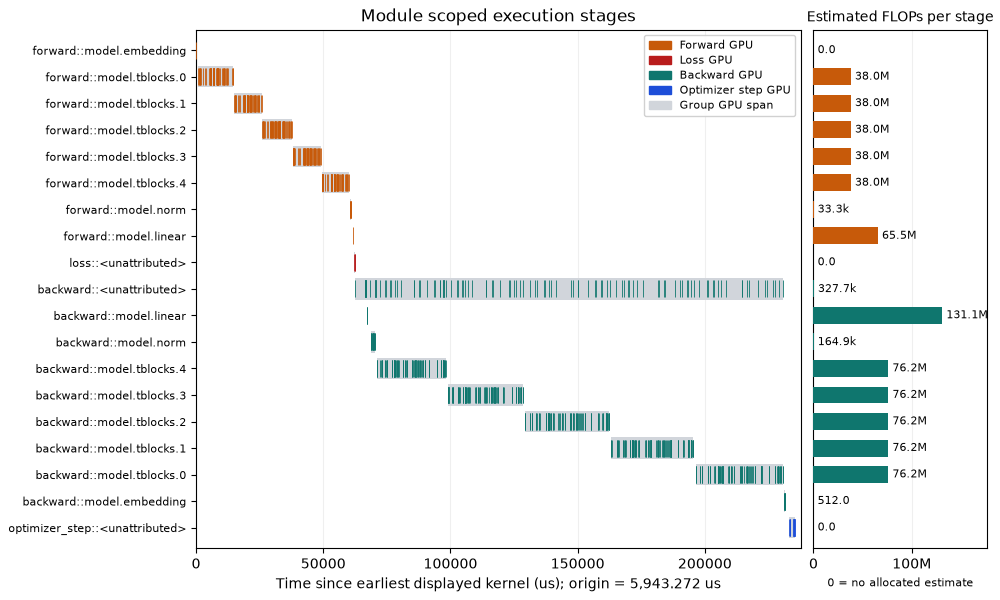

In [35]:
# Use the toolbar to zoom/pan; details stay in the kernels DataFrame.
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "widget")
display_timeline(groups, kernels, figsize=(10,6), show_flops=True)


In [30]:
(380 + 131) /(190 + 63)

2.0197628458498023

In [ ]:
# Analytical comparison for this TransformerLM (multiply + add = 2 FLOPs).
# Use all B*S input tokens: the model computes logits for every position before
# the loss slices off the final token. Attention forms full S x S matrices and
# then masks them; this implementation does not skip triangular matrix work.
p = model_parameters
batch, sequence = tokens.shape
n_tokens = batch * sequence
d_model, d_ff, layers, vocab = p.d_model, p.d_ff, p.num_layers, p.vocab_size
parameter_count = sum(parameter.numel() for parameter in model.parameters())
# Four attention projections, three SwiGLU projections per block, plus LM head.
# Exclude the lookup embedding and RMSNorm gains from this dense-matmul formula.
dense_parameters = layers * (4 * d_model**2 + 3 * d_model * d_ff) + d_model * vocab
forward_dense_flops = 2 * n_tokens * dense_parameters
forward_attention_flops = 4 * batch * layers * sequence**2 * d_model  # QK^T and AV
forward_matmul_flops = forward_dense_flops + forward_attention_flops

# Full module ownership, independent of the plot's selected depth.
comparison_groups, _, comparison_sources = aggregate_kernels(rows, depth=None)
allocated_sources = comparison_sources.loc[comparison_sources["status"].eq("allocated")]
matrix_sources = allocated_sources.loc[
    allocated_sources["name"].isin(["aten::mm", "aten::bmm", "aten::addmm"])
]
parameter_flop_comparison = pd.DataFrame(
    {"analytical_matmul_flops": [forward_matmul_flops, 2 * forward_matmul_flops]},
    index=pd.Index(["forward", "backward"], name="phase"),
)
parameter_flop_comparison["profiler_matmul_flops"] = (
    matrix_sources.groupby("phase")["contribution_flops"].sum()
    .reindex(parameter_flop_comparison.index, fill_value=0)
)
parameter_flop_comparison["profiler_total_flops"] = (
    comparison_groups.groupby(level="phase")["estimated_flops"].sum()
    .reindex(parameter_flop_comparison.index, fill_value=0)
)
parameter_flop_comparison["profiler_other_flops"] = (
    parameter_flop_comparison["profiler_total_flops"] - parameter_flop_comparison["profiler_matmul_flops"]
)
parameter_flop_comparison["matmul_difference"] = (
    parameter_flop_comparison["profiler_matmul_flops"] - parameter_flop_comparison["analytical_matmul_flops"]
)
parameter_flop_comparison.loc["forward + backward"] = parameter_flop_comparison.sum()
print(f"Parameters: {parameter_count:,}; dense projection parameters: {dense_parameters:,}; tokens: {n_tokens:,}")
print(f"6 × all parameters × tokens: {6 * parameter_count * n_tokens / 1e6:,.3f} MFLOPs")
print("Comparison below in MFLOPs; matrix estimates exclude normalization, activations, loss and optimizer work.")
display(parameter_flop_comparison.div(1e6).round(6))

# Per-module matrix estimates, compared with the same counted ATen sources.
expected_stage_flops = {}
for phase, multiplier in [("forward", 1), ("backward", 2)]:
    for layer in range(layers):
        expected_stage_flops[(phase, f"model.tblocks.{layer}.attention")] = multiplier * (
            8 * n_tokens * d_model**2 + 4 * batch * sequence**2 * d_model
        )
        expected_stage_flops[(phase, f"model.tblocks.{layer}.ffn")] = multiplier * (
            6 * n_tokens * d_model * d_ff
        )
    expected_stage_flops[(phase, "model.linear")] = multiplier * 2 * n_tokens * d_model * vocab
stage_matmul_comparison = pd.Series(expected_stage_flops, name="analytical_matmul_flops").to_frame()
stage_matmul_comparison.index.names = ["phase", "module_fqn"]
measured_stage_flops = matrix_sources.groupby(["phase", "module_fqn"])["contribution_flops"].sum()
# Outer join retains unexpected measured matrix work instead of hiding it.
stage_matmul_comparison = stage_matmul_comparison.join(
    measured_stage_flops.rename("profiler_matmul_flops"), how="outer",
).fillna(0)
stage_matmul_comparison["difference"] = (
    stage_matmul_comparison["profiler_matmul_flops"] - stage_matmul_comparison["analytical_matmul_flops"]
)
display(stage_matmul_comparison.div(1e6).round(6))
# 0 reported non-matrix FLOPs is not proof of zero work: many operations have
# no estimate. Backward = 2*forward applies to this unfrozen dense model's
# matmuls; freezing weights, detaching tensors or changing the model alters it.
